# Projet ML kaggle : Give me some credits

## Remise en contexte : détailler + PROBLEMATIQUE

## 1. La mise en route
### 1.A Import des modules

In [5]:
# Imports des modules nécessaires

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split

### 1.B Import des données

In [6]:
# Imports du jeu de données cs-training.csv

df = pd.read_csv("cs-training.csv", index_col=0)
print("Taille du jeu de données :", df.shape)

# On regarde la proportion respectivement de 0 et 1 dans la colonne cible SeriousDlqin2yrs
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

Taille du jeu de données : (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


### 1.C Préparation des des données d'entraînement et de test

In [7]:
# Découpage du jeu de données cs-training.csv en un jeu d'entraînement et un jeu de test

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
0.06684166666666666 0.06683333333333333


## 2. L'exploration des données
### 2.A Description générale du jeu de données train

In [8]:
train = X_train.copy()
train["SeriousDlqin2yrs"] = y_train

print("\nStructure des données de train : \n------------------")
train.info()                    # On repère notamment les valeurs manquantes et le type des variables
print("\nQuelques statistiques descriptives : \n------------------")
train.describe().T


Structure des données de train : 
------------------
<class 'pandas.core.frame.DataFrame'>
Index: 120000 entries, 57837 to 80531
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 1   age                                   120000 non-null  int64  
 2   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 3   DebtRatio                             120000 non-null  float64
 4   MonthlyIncome                         96325 non-null   float64
 5   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 6   NumberOfTimes90DaysLate               120000 non-null  int64  
 7   NumberRealEstateLoansOrLines          120000 non-null  int64  
 8   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 9   NumberOfDependents                    116872 non-null  float64
 10  SeriousDlqin2yrs

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,120000.0,6.128916,253.361490,0.0,0.029593,0.153318,0.557832,50708.0
age,120000.0,52.287842,14.771274,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.420075,4.182138,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,352.271245,2093.709509,0.0,0.175330,0.366194,0.860833,329664.0
MonthlyIncome,96325.0,6651.507345,14541.181413,0.0,3400.000000,5390.000000,8238.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.465692,5.161693,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.264942,4.158242,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.018167,1.133055,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.239858,4.144569,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,116872.0,0.757333,1.115337,0.0,0.000000,0.000000,1.000000,20.0


### 2.B Description des valeurs manquantes

In [9]:
print("\nProportion de valeurs manquantes dans chaque variable du jeu de données train : \n------------------")
missing = train.isna().mean().sort_values(ascending=False) * 100
print(missing[missing > 0].round(2))

# On regarde la proportion de défauts de paiement en fonction des variables avec valeurs manquantes
print("\nLes manquants sont-ils corrélés avec la variable cible ? \n------------------")
for i in ["MonthlyIncome", "NumberOfDependents"]:
    taux = train.groupby(train[i].isna())["SeriousDlqin2yrs"].mean()
    print(i, "\n", taux.rename({False: "renseigné", True: "manquant"}), "\n")



Proportion de valeurs manquantes dans chaque variable du jeu de données train : 
------------------
MonthlyIncome         19.73
NumberOfDependents     2.61
dtype: float64

Les manquants sont-ils corrélés avec la variable cible ? 
------------------
MonthlyIncome 
 MonthlyIncome
renseigné    0.069577
manquant     0.055713
Name: SeriousDlqin2yrs, dtype: float64 

NumberOfDependents 
 NumberOfDependents
renseigné    0.067450
manquant     0.044118
Name: SeriousDlqin2yrs, dtype: float64 



<div style="color: #eb65f0;">

##### Ce qu'on observe : 2 variables contiennent des valeurs manquantes

- Près de 20% des personnes n'ont pas renseigné leur revenu mensuel (MonthlyIncome)
- On a 2,6% de valeurs manquantes sur le nombre de personnes à charge (NumberOfDependents)

##### Comment interpréter les valeurs manquantes ?

On calcule le taux de défaut de paiement dans chaque groupe qui contient des manquants.
On remarque cependant qu'on ne peut pas conclure sur l'association entre l'absence de revenus indiquée et un potentiel défaut de paiement.

</div>


### 2.C Analyse des valeurs suspectes

In [21]:
print("Âge < 18 ans :", (train["age"] <18 ).sum())
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    valeurs = train[train[col] > 1][col]
    print(col, "/ nombre :", len(valeurs), "/ moyenne :", round(valeurs.mean(), 2), "/ médiane :", round(valeurs.median(), 2))

retards = ["NumberOfTime30-59DaysPastDueNotWorse",
           "NumberOfTimes90DaysLate",
           "NumberOfTime60-89DaysPastDueNotWorse"]
for c in retards:
    print(c, train[c].value_counts().sort_index().tail(6).to_dict())

print("Doublons :", train.duplicated().sum())

Âge < 18 ans : 1
RevolvingUtilizationOfUnsecuredLines / nombre : 2640 / moyenne : 265.11 / médiane : 1.08
DebtRatio / nombre : 27987 / moyenne : 1509.44 / médiane : 913.0
NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 2, 13: 1, 96: 2, 98: 212}
NumberOfTimes90DaysLate {13: 3, 14: 2, 15: 2, 17: 1, 96: 2, 98: 212}
NumberOfTime60-89DaysPastDueNotWorse {7: 8, 8: 1, 9: 1, 11: 1, 96: 2, 98: 212}
Doublons : 437


<div style="color: #eb65f0;">

##### Ce qu'on observe : certaines données qui attirent l'attention
- Des clients qui seraient mineurs : cela pourrait être soit une erreur de saisie, soit une donnée manquante pour l'âge remplacée par un 0

- **Le ratio d'utilisation de crédit > 1** : n'est pas alarmant en soi, mais pourrait être un indicateur pour l'interprétation des résultats plus tard. On remarque des données très aberrantes avec une moyenne 265 fois supérieure à la médiane, donc tirée par ces valeurs aberrantes.

- **Le ratio de dette > 1** : n'est pas non plus alarmant en soi, mais comme ce ratio dépend du revenu mensuel pour lequel on a beaucoup de données manquantes (20%), il faut rester vigilant aux erreurs de calcul. Ici ce n'est pas une anomalie rare car plus de 27000 lignes la contiennent, soit presque 20% du nombre de lignes tout comme le nombre de données manquantes en MonthlyIncome : on a donc des aberrations sur le ratio de dettes à cause des données manquantes de MonthlyIncome et des données = 0.

##### Les retards de paiement
- Concernant les retards : certains chiffres très élevés comme 96 ou 98 apparaissant près de 214 fois par variables peuvent représenter des anomalies de saisie ou de calcul, ou bien codes à déchiffrer lors de l'apprentissage. Il est assez étrange d'avoir un client ayant dépassé 96 ou 98 fois les 30 jours de retards de paiement en 2 ans.

##### Les doublons
On a 437 doublons qui peuvent fausser les données. Cependant plusieurs clients peuvent avoir les mêmes lignes descriptives.

</div>

### 2.D Etude des distributions graphiques des données

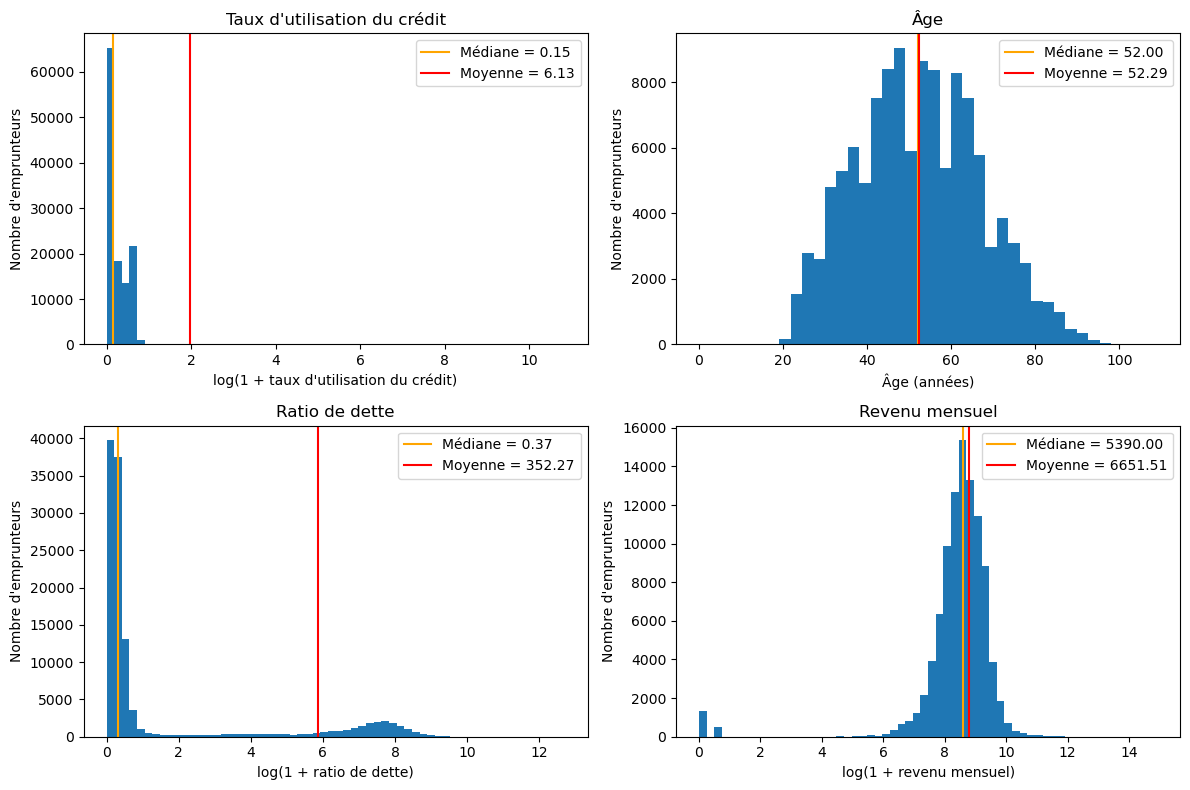

In [33]:
variables = {"RevolvingUtilizationOfUnsecuredLines": "Taux d'utilisation du crédit",
             "age": "Âge","DebtRatio": "Ratio de dette","MonthlyIncome": "Revenu mensuel",}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (col, nom) in zip(axes.ravel(), variables.items()):
    valeurs = train[col].dropna()                      # On supprime les valeurs manquantes pour ne pas fausser les calculs de moyenne et médiane
    mediane = valeurs.median()
    moyenne = valeurs.mean()

    if col == "age":                                            # Age n'a pas besoin d'échelle logarithmique
        ax.hist(valeurs, bins=40)
        ax.set_xlabel("Âge (années)")
        position_mediane, position_moyenne = mediane, moyenne
    else:                                                       # Autres variables : échelle logarithmique
        ax.hist(np.log1p(valeurs), bins=60)
        ax.set_xlabel(f"log(1 + {nom.lower()})")
        position_mediane, position_moyenne = np.log1p(mediane), np.log1p(moyenne)

    ax.axvline(position_mediane, color="orange", label=f"Médiane = {mediane:.2f}")
    ax.axvline(position_moyenne, color="red", label=f"Moyenne = {moyenne:.2f}")
    ax.set_title(nom)
    ax.set_ylabel("Nombre d'emprunteurs")
    ax.legend()

plt.tight_layout()
plt.show()

In [34]:
train["tranche_age"] = pd.cut(train["age"], bins=[0, 25, 35, 45, 55, 65, 120])
print(train.groupby("tranche_age", observed=True)["SeriousDlqin2yrs"].agg(["mean", "count"]))

corr = train.drop(columns="tranche_age").corr(method="spearman")["SeriousDlqin2yrs"]
print(corr.drop("SeriousDlqin2yrs").sort_values())

                 mean  count
tranche_age                 
(0, 25]      0.109980   2455
(25, 35]     0.108688  14721
(35, 45]     0.088126  23875
(45, 55]     0.076136  29329
(55, 65]     0.046733  26769
(65, 120]    0.024639  22850
age                                    -0.113887
MonthlyIncome                          -0.065582
NumberOfOpenCreditLinesAndLoans        -0.041060
NumberRealEstateLoansOrLines           -0.033924
DebtRatio                               0.019206
NumberOfDependents                      0.046135
RevolvingUtilizationOfUnsecuredLines    0.240463
NumberOfTime30-59DaysPastDueNotWorse    0.254833
NumberOfTime60-89DaysPastDueNotWorse    0.278078
NumberOfTimes90DaysLate                 0.343674
Name: SeriousDlqin2yrs, dtype: float64
